# Day 15 — Political News Coverage Analyzer: analysis

Compare topics, attention, and language sentiment across an explicitly
defined news corpus: six outlet RSS feeds, window 2026-11-08–2026-11-22,
title + description text only.

Sentiment measures the emotional tone of the words used; it is not a measure of factual accuracy, fairness, or political bias.


This notebook is descriptive only: no predictive model, no bias score,
no leaning score, no fact-checking, no causal claims. It never downloads
data itself — it reads the committed processed files.

In [1]:
from pathlib import Path
import json
import pandas as pd

def _find_root() -> Path:
    # Resolve the project root from this notebook file's own location,
    # never from the working directory (Day 1 lesson (e)).
    here = Path("analysis.ipynb").resolve().parent
    for cand in [here, here.parent, Path.cwd(), Path.cwd().parent]:
        if (cand / "data" / "processed" / "articles.csv").exists():
            return cand
    raise FileNotFoundError("Could not find data/processed/articles.csv from " + str(here))

ROOT = _find_root()
PROC = ROOT / "data" / "processed"
record = json.loads((PROC / "data_source.json").read_text(encoding="utf-8"))
stats = json.loads((PROC / "stats_results.json").read_text(encoding="utf-8"))
articles = pd.read_csv(PROC / "articles.csv")
attention = pd.read_csv(PROC / "topic_attention.csv")
by_outlet = pd.read_csv(PROC / "sentiment_by_outlet.csv")
by_topic = pd.read_csv(PROC / "sentiment_by_topic.csv")
sample = pd.read_csv(PROC / "sample_review.csv")
print("Root:", ROOT)
print("Corpus:", len(articles), "articles;", record["per_outlet_n"])

Root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-15-political-news-coverage-analyzer
Corpus: 75 articles; {'NYT': 10, 'WSJ': 0, 'Fox News': 24, 'CNN': 0, 'NPR': 10, 'BBC News': 31}


In [2]:
# Audit: row counts, window-filter drops, duplicates, coverage achieved
for outlet, info in record["outlets"].items():
    print(f"{outlet:>9}: fetched {info['fetched_items']:>2}, "
          f"missing link/date {info['dropped_missing_link_or_date']}, "
          f"outside window {info['dropped_outside_window']}, "
          f"duplicates {info['duplicates_removed']}, final n={info['final_n']}, "
          f"window {info['earliest_pub_date']} to {info['latest_pub_date']}")
# Corpus-integrity checks (plan §3.3) — any failure stops the analysis
checks = record["cross_checks"]["corpus_integrity"]
print("Corpus integrity:", checks)
assert all(checks.values())
assert len(articles) == sum(record["per_outlet_n"].values()) == 75
assert articles["link"].is_unique
print("VADER recompute (5 titles, direct call):",
      record["cross_checks"]["vader_recompute_5_titles"]["max_abs_diff"],
      "max abs diff at 3 decimals")
print("Manual validation (§4.4):", record["manual_validation"]["cell"],
      record["manual_validation"]["hand_share_pct"], "% — diff",
      record["manual_validation"]["share_diff_pp"], "pp")

      NYT: fetched 10, missing link/date 0, outside window 0, duplicates 0, final n=10, window 2026-11-20 to 2026-11-22
      WSJ: fetched 20, missing link/date 0, outside window 20, duplicates 0, final n=0, window None to None
 Fox News: fetched 25, missing link/date 0, outside window 1, duplicates 0, final n=24, window 2026-11-22 to 2026-11-22
      CNN: fetched 50, missing link/date 4, outside window 46, duplicates 0, final n=0, window None to None
      NPR: fetched 10, missing link/date 0, outside window 0, duplicates 0, final n=10, window 2026-11-21 to 2026-11-22
 BBC News: fetched 33, missing link/date 0, outside window 2, duplicates 0, final n=31, window 2026-11-11 to 2026-11-22
Corpus integrity: {'all_pub_dates_in_window': True, 'urls_unique': True, 'per_outlet_counts_sum_to_total': True, 'exactly_one_topic_per_article': True, 'all_compounds_in_range': True, 'all_labels_valid': True}
VADER recompute (5 titles, direct call): 0.0 max abs diff at 3 decimals
Manual validation (§4.

## Q1 — What topics did each outlet cover, and how much attention did each topic get?

Attention share = articles(outlet, topic) ÷ articles(outlet, all topics) × 100,
with a Wilson 95% CI. Raw counts are never compared across outlets as
"attention" without the share beside them.

In [3]:
# Corpus-wide attention shares (all 10 topics)
corpus_wide = attention[attention["outlet"] == "ALL"].sort_values(
    "attention_share_pct", ascending=False
)[["topic", "n_articles", "attention_share_pct", "wilson_ci_low", "wilson_ci_high"]]
corpus_wide
print("Largest attention-share cell:")
top = attention[attention["outlet"] != "ALL"].sort_values(
    "attention_share_pct", ascending=False
).iloc[0]
print(f"{top['outlet']} x {top['topic']}: {top['n_articles']}/{top['outlet_total']} "
      f"= {top['attention_share_pct']:.2f}% "
      f"(Wilson 95% CI {top['wilson_ci_low']:.2f}–{top['wilson_ci_high']:.2f})")

Largest attention-share cell:
BBC News x Other: 19/31 = 61.29% (Wilson 95% CI 43.82–76.27)


## Q2 — How does the language sentiment of coverage differ across outlets and topics?

VADER compound on title + description (original-cased text); thresholds
±0.05. Mean with 95% CI (t-interval, or bootstrap with 1,000 resamples
when |skew| > 1), median, and % positive / neutral / negative. Sentiment
is language tone only — VADER was not built for news text.

In [4]:
by_outlet
print("Groups with n >= 5 (sentiment by topic):")
by_topic[by_topic["n"] >= 5][
    ["outlet", "topic", "n", "mean_compound", "ci_low", "ci_high", "median_compound"]
]

Groups with n >= 5 (sentiment by topic):


,outlet,topic,n,mean_compound,ci_low,ci_high,median_compound
4,NYT,Other,5,0.206360,-0.368264,0.780984,0.1531
9,Fox News,Technology & AI,9,-0.004211,-0.363827,0.355405,-0.0490
11,Fox News,Other,5,0.501400,0.035194,0.967606,0.4019
22,BBC News,Technology & AI,5,0.206800,-0.597190,1.000000,0.0000
24,BBC News,Other,19,0.184626,-0.090401,0.459654,0.2185


In [5]:
# Statistical comparisons (plan §4.3)
chi = stats["chi_square_topic_outlet"]
print(f"Chi-square topic x outlet: chi2={chi['chi2']:.2f}, df={chi['df']}, "
      f"asymptotic p={chi['p_value']:.3f}, min expected={chi['min_expected']:.2f}")
print(f"Collapsed table: chi2={chi['collapsed_chi2']:.2f}, "
      f"p={chi['collapsed_p_value']:.3f}")
print(f"Permutation p-value (10,000 shuffles, seed 42): {chi['permutation_p_value']:.4f}")
print("Conclusion rests on:", chi["conclusion_basis"])
sent = stats["sentiment_by_outlet"]
print(f"\nSentiment by outlet ({sent['test']}): statistic={sent['statistic']:.2f}, "
      f"p={sent['p_value']:.3f} — {sent['why']}")
print("Pairwise (Mann-Whitney U, Bonferroni-corrected p-values):")
import pandas as pd
pd.DataFrame(stats["pairwise_tests"])[["outlet_a", "outlet_b", "mean_diff", "p_value"]]
for outlet, result in stats["sentiment_by_topic_within_outlet"].items():
    print(outlet, "->", result["test"], "p =", result.get("p_value"))

Chi-square topic x outlet: chi2=31.94, df=27, asymptotic p=0.234, min expected=0.13
Collapsed table: chi2=18.90, p=0.091
Permutation p-value (10,000 shuffles, seed 42): 0.2214
Conclusion rests on: permutation p-value (10,000 shuffles, seed 42) on the full table; the asymptotic p-value is reported alongside but the conclusion rests on the permutation p-value

Sentiment by outlet (Kruskal-Wallis): statistic=2.09, p=0.553 — at least one outlet failed Shapiro-Wilk normality (p <= 0.05)
Pairwise (Mann-Whitney U, Bonferroni-corrected p-values):
NYT -> not run p = None
WSJ -> not run p = None
Fox News -> one-way ANOVA p = 0.061350164708392385
CNN -> not run p = None
NPR -> not run p = None
BBC News -> one-way ANOVA p = 0.9406040014951986


## Q3 — Are the differences larger than chance?

Chi-square (permutation p = 0.221) and Kruskal-Wallis (p = 0.553) both say
no: in this 75-article corpus, neither the distribution of topics nor the
average language tone differs across outlets by more than chance would
allow. That is a statement about this corpus and window, not about the
outlets in general.

## Sample review

Stratified sample, 5 articles per outlet with articles in the window,
seed 42, drawn once and fixed. WSJ and CNN had no articles to sample,
so the drawn sample is 20 articles, not 30 (the plan's 30-article design
assumes 5 per outlet across all six). The review is complete:
agreement rate 55.0% (11 of 20 reviewed articles) — BBC News 2/5,
Fox News 2/5, NPR 4/5, NYT 3/5 — reported next to every topic finding.

In [6]:
sample[["outlet", "title", "assigned_topic", "reviewer_topic", "agree"]]
reviewed = sample[sample["reviewer_topic"].notna() & (sample["reviewer_topic"] != "")]
print("Reviewed so far:", len(reviewed), "of", len(sample))
if len(reviewed):
    agree = (reviewed["agree"].astype(str).str.lower() == "true").sum()
    print(f"Agreement rate: {agree / len(reviewed) * 100:.1f}% ({agree}/{len(reviewed)})")
else:
    print("Agreement rate: pending tester review")

Reviewed so far: 20 of 20
Agreement rate: 55.0% (11/20)


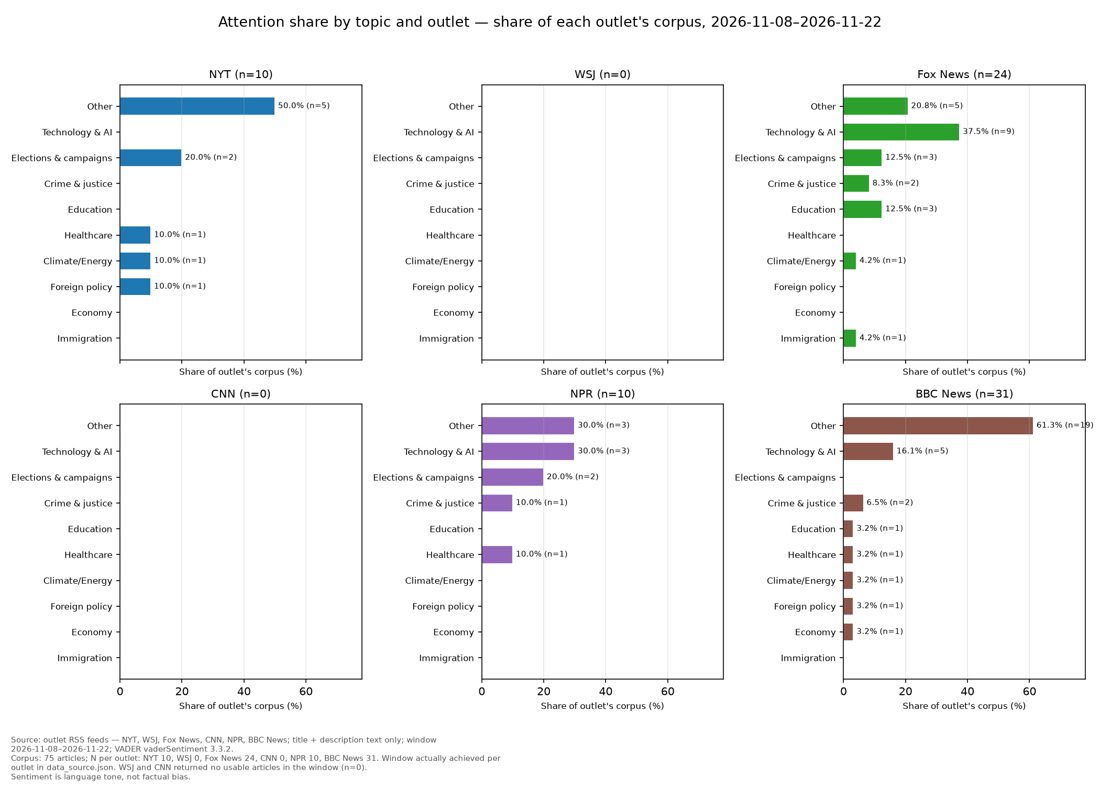

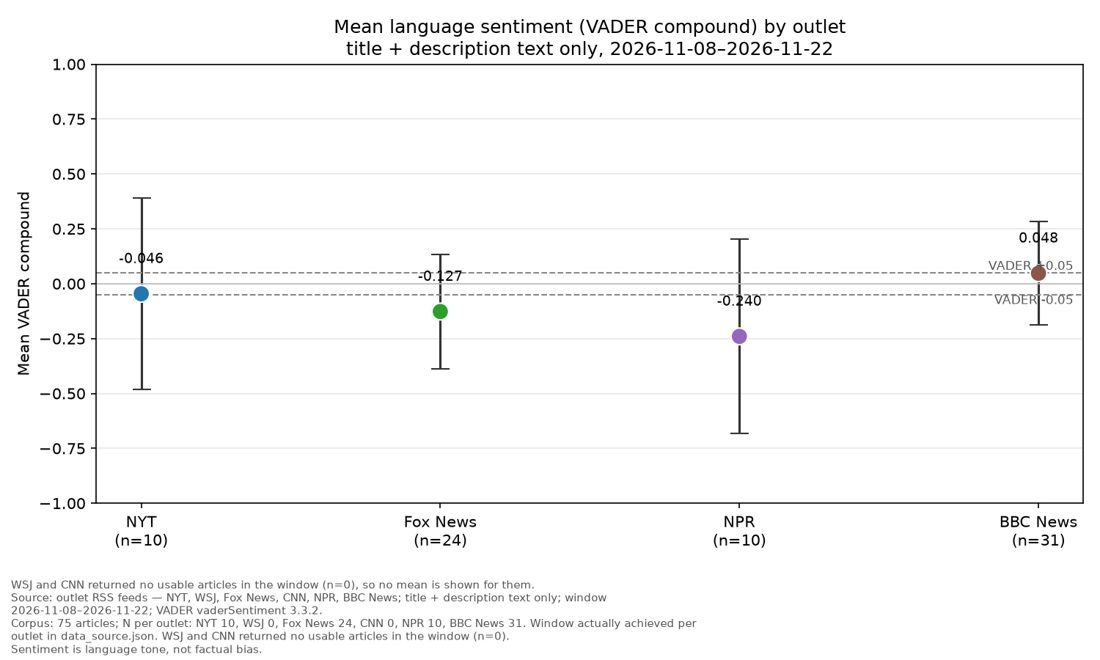

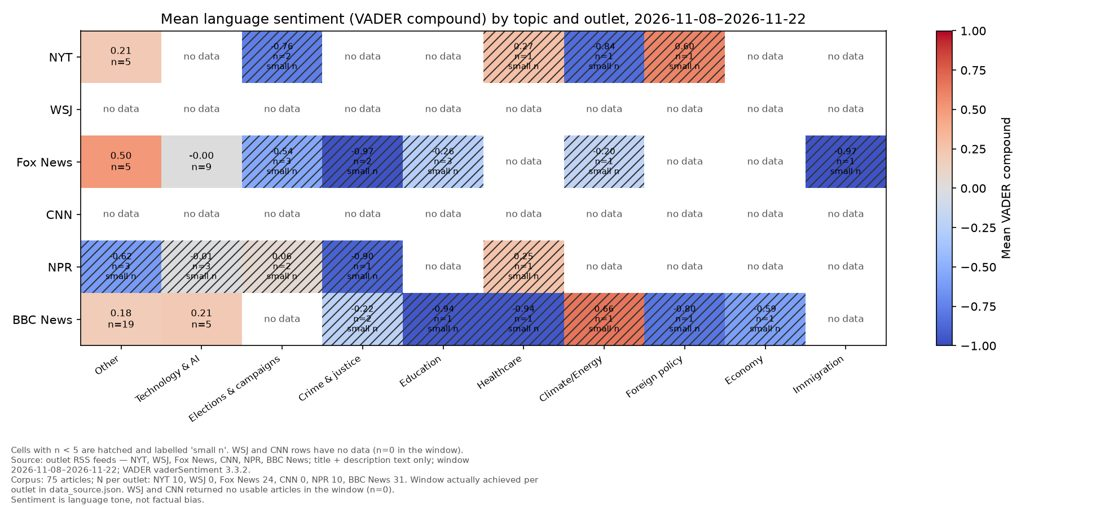

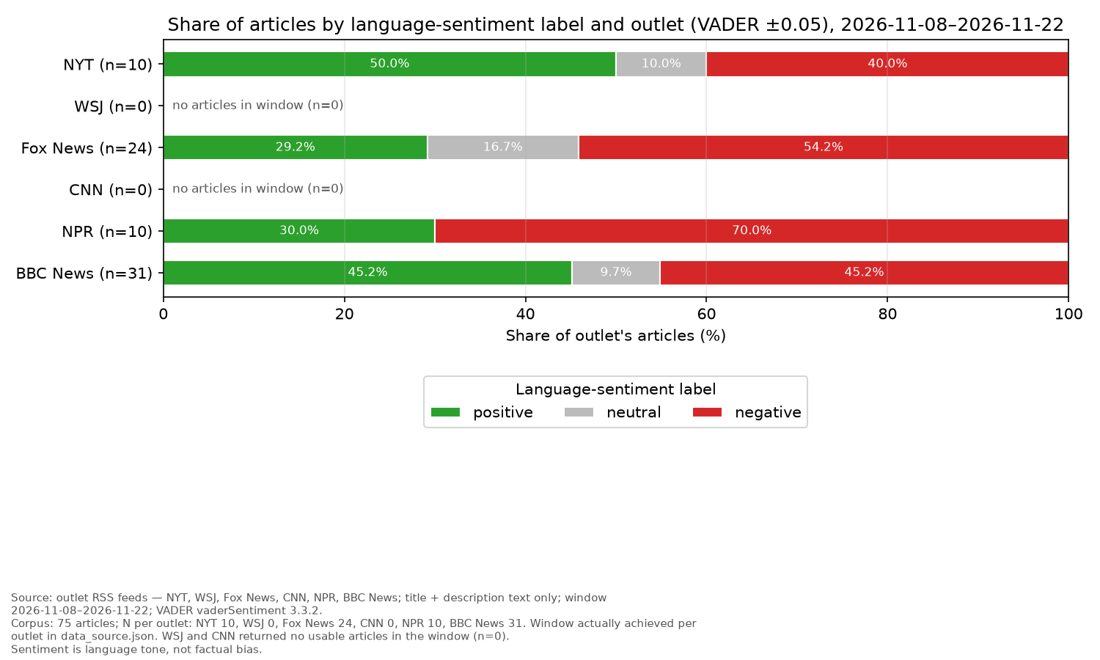

In [7]:
# The 4 charts, inline (downscaled JPEG copies so the notebook stays
# under 1 MB; the standalone PNGs in outputs/charts/ are full resolution)
import io
from IPython.display import Image, display
from PIL import Image as PILImage
for name in ["01_attention_share_by_topic", "02_mean_sentiment_by_outlet",
             "03_sentiment_by_topic_heatmap", "04_sentiment_distribution"]:
    with PILImage.open(ROOT / "outputs" / "charts" / f"{name}.png") as im:
        im.thumbnail((1100, 1100))
        buf = io.BytesIO()
        im.convert("RGB").save(buf, format="JPEG", quality=82)
    display(Image(data=buf.getvalue(), format="jpeg"))

## Limitations

- Sentiment is language tone only — never a measure of factual accuracy,
  fairness, or political bias. VADER is a general-purpose social-media
  lexicon, not built for news text.
- Title + description text only — no full article text; no scraping of
  linked article pages.
- Descriptive only — no predictive model, no bias score, no leaning
  score, no fact-checking, no causal claims.
- Keyword matching is crude — a headline can mention a word without
  being about that topic; the sample-review agreement rate 55.0%
  (11 of 20; BBC News 2/5, Fox News 2/5, NPR 4/5, NYT 3/5) is the
  honest measure of the dictionary's trustworthiness.
- Small, uneven corpus (75 articles; WSJ and CNN n=0; NYT and NPR
  n=10 each) and sparse topic × outlet cells — hence the permutation
  p-value.
- Rolling feeds: the window actually achieved per outlet is shorter
  than 14 days for every outlet (best: BBC News, 12 days).
- GDELT not used (optional cross-check only; skipped — verified
  rate-limited by the researcher).

## Conclusion

For the same two weeks, in the articles these feeds actually served,
the four outlets with articles covered a similar mix of topics (mostly
uncategorised by the frozen dictionary, then Technology & AI), and
their headline + summary language sounded statistically
indistinguishable on average. That is the whole finding.